# German reunification

GDP per capita, 1960–2003; first comparison post-period 1990. Outcome: GDP per capita in PPP-adjusted current US dollars, following the authors' 2025 erratum.

Abadie, Diamond and Hainmueller (2015), [AJPS](https://doi.org/10.1111/ajps.12116). The historical two-stage predictor-weight specification is checked against the pysyncon reference ATT −1555.13468, with its predeclared 2.5% numerical tolerance. That reference includes 1990 in predictor means and the training validation window. We retain this historical convention explicitly; all common-comparison models below fit only years **strictly before 1990**.

Run from a checkout installed using `requirements-replication.txt` and `pip install -e .`. Full execution also needs the separately supplied local reference bundle, which is excluded from this repository. Once it is provisioned, install the original R dependencies with `python .local/reference/scripts/install_r_references.py --library .r-library` after following [the R setup guide](../docs/reference_backends.md). The notebook downloads immutable public data with **requests**, checks the reference specification, and exports three publication figures locally as PDF, SVG and 300 dpi PNG. The figures are embedded below; generated exports stay outside version control. See [the replication guide](../docs/replication.md) and [the figure guide](../docs/plotting.md).

In [1]:
%matplotlib inline
import hashlib
import os
import json
import time
from dataclasses import replace
from io import BytesIO
from pathlib import Path
from importlib.metadata import version

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
from IPython.display import Markdown, display

from pysynth import (
    SyntheticControl, SCUL, IndividualSC, TwoStageIndividualSC,
    SyntheticDID, DifferenceInDifferences, PySyncon, SCM, compare,
    plot_paths, plot_effects, plot_comparison, save_figure,
)
from pysynth.datasets import DATASETS
from pysynth.replication import (
    LITERATURE_BENCHMARKS, replicate, check_replication, reference_comparisons,
    california_paper_inference,
)
from pysynth.plotting import reference_comparison_table

pd.Series({p: version(p) for p in [
    'pysynth-control', 'numpy', 'scipy', 'pandas', 'matplotlib',
    'pysyncon', 'SyntheticControlMethods',
]}, name='version')

pysynth-control             0.1.0
numpy                       2.0.2
scipy                      1.13.1
pandas                      2.3.3
matplotlib                  3.9.4
pysyncon                    1.7.0
SyntheticControlMethods    1.1.17
Name: version, dtype: object

## Download and verify the academic data

The URL names an immutable upstream commit. SHA256 verification fails
visibly if the bytes differ. No manual download or bundled data is required.

In [2]:
name = 'germany'
spec = DATASETS[name]
response = requests.get(spec.url, timeout=30)
response.raise_for_status()
assert hashlib.sha256(response.content).hexdigest() == spec.sha256
data = pd.read_csv(BytesIO(response.content), sep=spec.separator)
panel = spec.panel(data)
print(spec.citation)
print(spec.url)
print(f'{panel.n_control} donors; {panel.n_pre} pre-periods; {panel.n_post} post-periods')
data.head()

Abadie, Diamond & Hainmueller (2015), doi:10.1111/ajps.12116
https://raw.githubusercontent.com/sdfordham/pysyncon/b77dc20e29b012ab03ca1d4caeef7b41861e86f5/data/germany.csv
16 donors; 30 pre-periods; 14 post-periods


,code,country,year,gdp,infrate,trade,schooling,invest60,invest70,invest80,industry
0,1,USA,1960,2879,NaN,9.693181,43.799999,NaN,NaN,NaN,NaN
1,1,USA,1961,2929,1.075182,9.444655,NaN,NaN,NaN,NaN,NaN
2,1,USA,1962,3103,1.116071,9.429324,NaN,NaN,NaN,NaN,NaN
3,1,USA,1963,3227,1.214128,9.470706,NaN,NaN,NaN,NaN,NaN
4,1,USA,1964,3420,1.308615,9.725879,NaN,NaN,NaN,NaN,NaN


## Reference specification and numerical check

This uses the historical specification above. Its numerical assertion is
separate from the new-method comparison. The path figure identifies the
reference estimator explicitly. See `pysynth.replication.replicate` for
predictor windows and optimization settings.

The warm-toned annotation gives the source-reported result at its stated
precision, with a source link and specification context. It is separate
from the numerical replication check. See the
[benchmark provenance](../docs/replication.md#literature-annotations)
for the paper/author-example distinction, compatible units, and the
German paper's 2025 erratum.

,label,source_label,reference,reproduced,difference,units,difference_units,window_start,window_end,statistic,approximate,citation,source_url,context
0,Historical SCM,Published,-1600.000000,-1555.134678,4.486532e+01,PPP current US$ per capita,PPP current US$ per capita,1990,2003,mean_effect,True,"Abadie, Diamond & Hainmueller (2015), p. 504 ·...",https://economics.mit.edu/sites/default/files/...,Approximate paper headline. Units follow the a...
1,Historical SCM,Upstream software,-1555.134678,-1555.134678,4.547474e-13,PPP current US$ per capita,PPP current US$ per capita,1990,2003,mean_effect,False,pysyncon parity fixture · b77dc20,https://github.com/sdfordham/pysyncon/blob/b77...,Historical predictor specification. This preci...


source                pysyncon reference ATT, 1990–2003
estimate                                   -1555.134678
reference                                  -1555.134678
absolute_tolerance                            38.878367
Name: Replication check, dtype: object

**Local figure exports** (relative to the notebook directory): `figures/germany/germany-reference.pdf` · `figures/germany/germany-reference.svg` · `figures/germany/germany-reference.png`

**Literature source:** [Abadie, Diamond & Hainmueller (2015), p. 504 · 1990–2003](https://economics.mit.edu/sites/default/files/publications/Comparative%20Politics%20and%20the%20Synthetic%20Control.pdf#page=10)

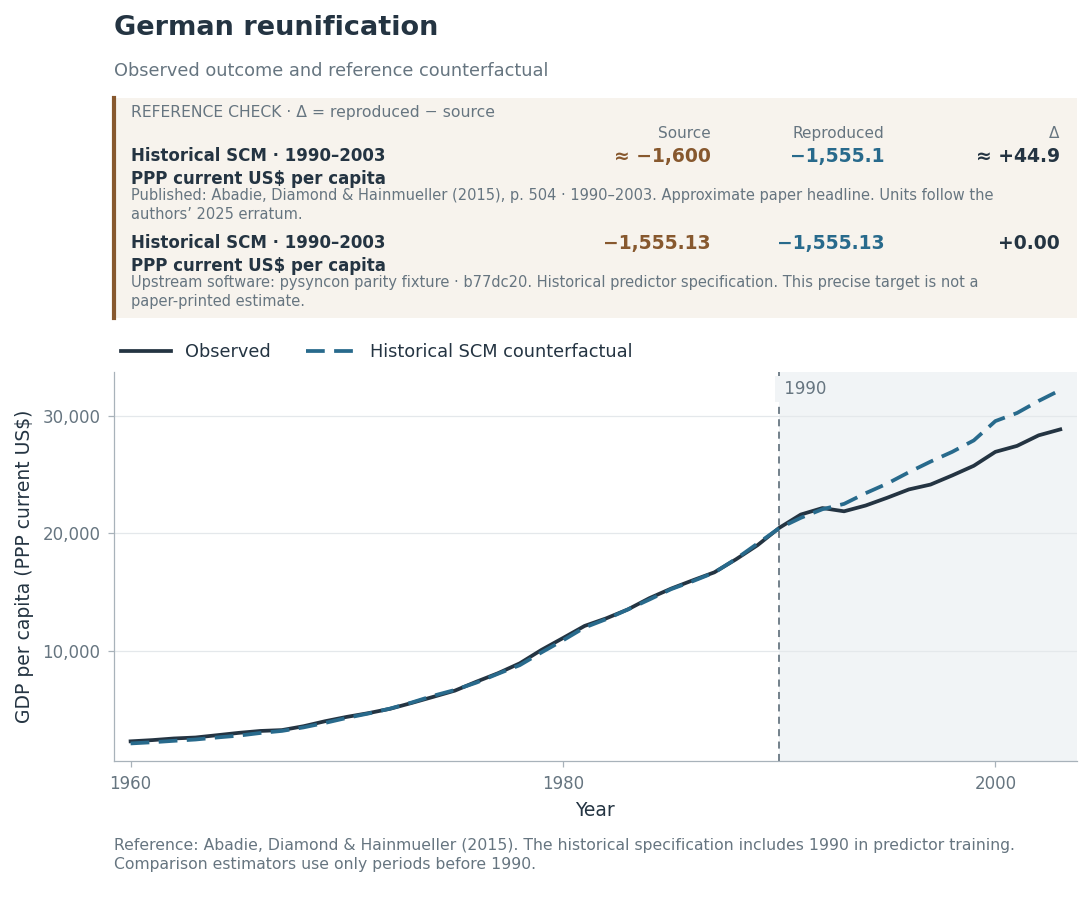

In [3]:
figure_details = {'case': 'German reunification', 'outcome': 'GDP per capita (PPP current US$)', 'effect': 'Effect on GDP per capita (PPP current US$)', 'units': 'PPP current US$ per capita', 'periods': '1960–1989 pretreatment · 1990–2003 post-treatment · 16 donors', 'onset': '1990', 'reference': 'Historical SCM counterfactual', 'reference_note': 'Reference: Abadie, Diamond & Hainmueller (2015). The historical specification includes 1990 in predictor training. Comparison estimators use only periods before 1990.'}
benchmark = LITERATURE_BENCHMARKS[name]
# Works when the kernel starts in either the repository or notebook folder.
example_dir = Path.cwd() if Path.cwd().name == 'empirical_examples' else Path.cwd() / 'empirical_examples'
figure_dir = Path(os.environ.get('PYSYNTH_FIGURE_DIR', example_dir / 'figures')) / name
figure_dir.mkdir(parents=True, exist_ok=True)

def export_figure(fig, kind):
    paths = save_figure(fig, figure_dir / f'{name}-{kind}')
    paths_text = ' · '.join(
        f'`{os.path.relpath(p, example_dir)}`' for p in paths
    )
    display(Markdown('**Local figure exports** (relative to the notebook directory): ' + paths_text))
    display(Markdown(f'**Literature source:** [{benchmark.citation}]({benchmark.source_url})'))
    return paths

reference = replicate(name, data)
report = check_replication(name, reference)
additional = None
paper_uncertainty = None
if name == 'california':
    additional = {'SC': SyntheticDID().fit_sc(panel), 'DID': DifferenceInDifferences().fit(panel)}
    paper_uncertainty = california_paper_inference(panel, reference)
    se_reference = paper_uncertainty.metadata['paper_replication']['reference_standard_error']
    np.testing.assert_allclose(paper_uncertainty.standard_error, se_reference, atol=1e-9, rtol=0)
    assert abs(additional['SC'].att - (-19.6)) <= 0.05
    assert abs(additional['DID'].att - (-27.3)) <= 0.05
    report.update({'SE estimate': paper_uncertainty.standard_error,
                   'SE reference': se_reference, 'SE absolute tolerance': 1e-9})

def matched_references(fit, additional=None):
    refs = reference_comparisons(name, fit, additional=additional)
    if paper_uncertainty is not None:
        refs = [replace(r, context=r.context + (
            f' SE: paper 8.4; reproduced {paper_uncertainty.standard_error:.3f} '
            '(authors’ seed 12345).'
        )) if r.label == 'SDID' else r for r in refs]
    return refs

references = matched_references(reference, additional=additional)
reference_table = reference_comparison_table(references)
display(reference_table)
reference_table.to_csv(figure_dir / f'{name}-references.csv', index=False)
display(pd.Series(report, name='Replication check'))
ax = plot_paths(
    reference,
    title=figure_details['case'],
    subtitle='Observed outcome and reference counterfactual',
    ylabel=figure_details['outcome'], xlabel='Year',
    observed_label='Observed',
    counterfactual_label=figure_details['reference'],
    intervention_label=figure_details['onset'],
    references=references,
    note=figure_details['reference_note'],
)
reference_files = export_figure(ax.figure, 'reference')
plt.show()

## Fit all applicable methods on a common sample

Every comparison uses the same outcome panel, eligible donors and treatment
date. Classical pysyncon SCM estimates predictor importance by nested
optimization. SyntheticControlMethods uses **all pretreatment outcome
lags and all ten optimization starts**, with checked numerical recovery
when a gradient line search fails. Neither adapter truncates the fit
to accelerate this example. Native outcome SCM is retained as the
explicitly named equal-period baseline.

SCUL calls the pinned original R functions and glmnet, selecting
`lambda.median` from fold-specific paths. Its rolling validation windows
are stated in code. Basque has only ten pretreatment observations, so
its validation horizon must be shorter than its 28-period post window.
Penalized and robust SCM retain the explicit illustrative tuning values
shown below; these are new applications, not paper-specific calibrations.

ISC calls **MSCMT**, using the costofcare bootstrap workflow with **50
donor resamples**. 2SISC first selects up to ten nearest donors, then
runs the same ISC procedure within that group. These aggregate panels
do not provide the survey-specific demographic predictors, eligibility
rules, or individual sampling design of the original ISC studies.

SDID uses donor post-period outcomes to estimate time weights; robust
SCM uses them for donor denoising. Neither fits to treated post-outcomes.
Each model runs in full; failures stop execution. Elapsed fitting times
and optimizer diagnostics are exported alongside the estimates.

In [4]:
scul_windows = {'california': (5, 12), 'basque': (3, 5),
                'germany': (14, 14), 'kansas': (16, 16)}
initial, horizon = scul_windows[name]
models = {
    'Outcome SCM': SyntheticControl(),
    'SCUL': SCUL(initial_window=initial, horizon=horizon),
    'ISC (full donor pool)': IndividualSC(),
    '2SISC (nearest 10)': TwoStageIndividualSC(n_neighbors=10),
    'Synthetic DID': SyntheticDID(),
    'DID': DifferenceInDifferences(),
    'pysyncon SCM': PySyncon('synth'),
    'Augmented SCM': PySyncon('augsynth'),
    'Penalized SCM (0.01)': PySyncon('pensynth', options={'lambda_': 0.01}),
    'Robust SCM (rank 3, ridge 0.1)': PySyncon('robust', options={'lambda_': 0.1, 'sv_count': 3}),
    'SyntheticControlMethods SCM': SCM('synth'),
    'Differenced SCM': SCM('diffsynth'),
}
results, elapsed = {}, {}
for label, model in models.items():
    started = time.perf_counter()
    results[label] = model.fit(panel)
    elapsed[label] = time.perf_counter() - started
    print(f'{label}: {elapsed[label]:.2f} seconds')
comparison = compare(results)
comparison['elapsed_seconds'] = pd.Series(elapsed)
if name == 'california':
    references = matched_references(results['Synthetic DID'], additional={
        'SC': additional['SC'], 'DID': results['DID'],
    })
elif name == 'kansas':
    references = matched_references(results['Augmented SCM'])
diagnostics = {label: fit.metadata for label, fit in results.items()}
(figure_dir / f'{name}-diagnostics.json').write_text(
    json.dumps(diagnostics, indent=2, default=str) + '\n'
)
display_labels = {
    'ISC (full donor pool)': 'ISC · full donor pool',
    '2SISC (nearest 10)': '2SISC · nearest 10',
    'pysyncon SCM': 'SCM · pysyncon',
    'Penalized SCM (0.01)': 'Penalized SCM · λ = 0.01',
    'Robust SCM (rank 3, ridge 0.1)': 'Robust SCM · rank 3',
    'SyntheticControlMethods SCM': 'SCM · SCMethods',
    'Differenced SCM': 'Differenced SCM',
}
comparison.round(4)

Outcome SCM: 0.01 seconds


SCUL: 0.55 seconds


ISC (full donor pool): 0.57 seconds


2SISC (nearest 10): 0.57 seconds
Synthetic DID: 0.09 seconds
DID: 0.00 seconds


/home/jinx/CharlieRahal Dropbox/Charlie RAHAL/PySynth/src/pysynth/sdid.py:158: RuntimeWarning: SDID reached max_iter before the objective-decrease stopping rule
  return self._estimate(panel, self._settings(panel), sparsify=self.sparsify)


pysyncon SCM: 7.96 seconds


Augmented SCM: 0.29 seconds
Penalized SCM (0.01): 0.09 seconds
Robust SCM (rank 3, ridge 0.1): 0.00 seconds


SyntheticControlMethods SCM: 0.30 seconds


Differenced SCM: 8.48 seconds


,att,pre_rmse,donors_used,weight_sum,elapsed_seconds
model,,,,,
Outcome SCM,-1304.6958,60.8666,7,1.0000,0.0050
SCUL,-1463.2094,60.2132,8,1.0058,0.5541
ISC (full donor pool),-1298.5680,82.1369,14,1.0000,0.5746
2SISC (nearest 10),-1103.3586,222.7100,10,1.0000,0.5683
Synthetic DID,-1471.3949,100.5897,13,1.0000,0.0942
DID,603.9836,713.2782,16,1.0000,0.0006
pysyncon SCM,-1448.6512,66.3182,10,1.0000,7.9632
Augmented SCM,-1495.0864,33.2871,16,1.0000,0.2867
Penalized SCM (0.01),-1738.6838,76.5068,5,1.0000,0.0942


## Average effects and pretreatment fit

The left panel reports the average post-treatment gap (ATT); the right
reports pretreatment root mean squared error in the same outcome units.
Methods retain the same order in every figure. They are not ranked by
estimated effect or fit. Each dot is a point estimate: **there are no
estimated confidence intervals in these figures**. Better pretreatment
fit alone does not establish causal credibility.

The reference strip pairs each source result with its matched reproduction
and signed difference, using the same statistic and evaluation window.
Approximate paper headlines and numerical upstream examples are labelled
separately. They are not targets for every estimator.

**Local figure exports** (relative to the notebook directory): `figures/germany/germany-comparison.pdf` · `figures/germany/germany-comparison.svg` · `figures/germany/germany-comparison.png`

**Literature source:** [Abadie, Diamond & Hainmueller (2015), p. 504 · 1990–2003](https://economics.mit.edu/sites/default/files/publications/Comparative%20Politics%20and%20the%20Synthetic%20Control.pdf#page=10)

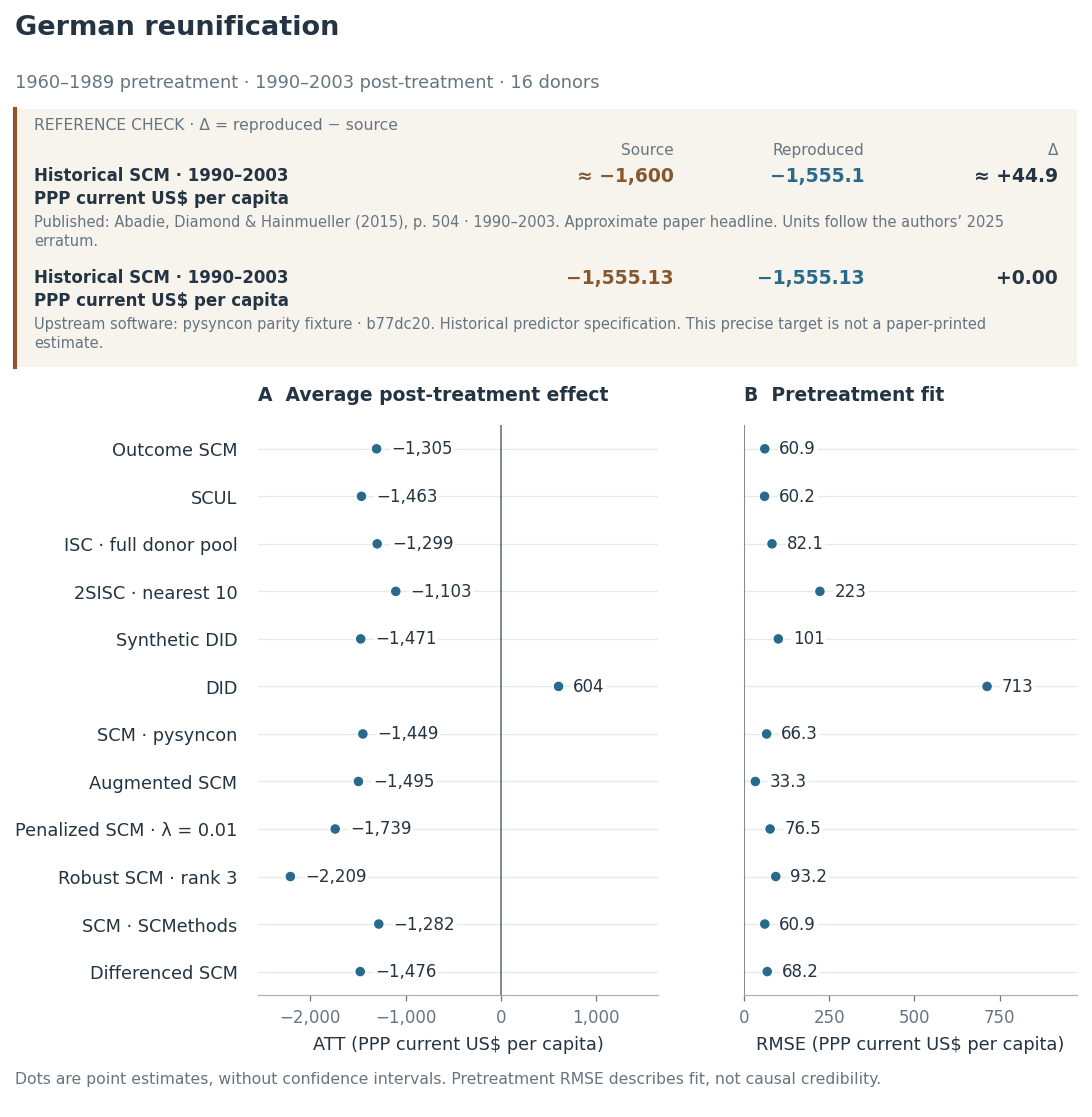

In [5]:
fig, axes = plot_comparison(
    results, labels=display_labels,
    title=figure_details['case'],
    subtitle=figure_details['periods'],
    units=figure_details['units'],
    references=references,
)
comparison_files = export_figure(fig, 'comparison')
comparison.to_csv(figure_dir / f'{name}-estimates.csv', float_format='%.12g')
plt.show()

## Effect paths on a common scale

Every panel shows **observed minus counterfactual**. All twelve panels
share the same horizontal and vertical scales; no extreme estimate is
clipped. The zero line denotes no estimated effect. The dashed vertical
line and shaded region identify the common treatment onset and post-period.
Shading does not represent uncertainty. Calendar spacing is preserved,
including quarterly observations. Panel labels replace repeated legends.
The source/reproduction strip uses matched specifications and windows.
Any numeric reference guide applies only to its matched estimator.

**Local figure exports** (relative to the notebook directory): `figures/germany/germany-effects.pdf` · `figures/germany/germany-effects.svg` · `figures/germany/germany-effects.png`

**Literature source:** [Abadie, Diamond & Hainmueller (2015), p. 504 · 1990–2003](https://economics.mit.edu/sites/default/files/publications/Comparative%20Politics%20and%20the%20Synthetic%20Control.pdf#page=10)

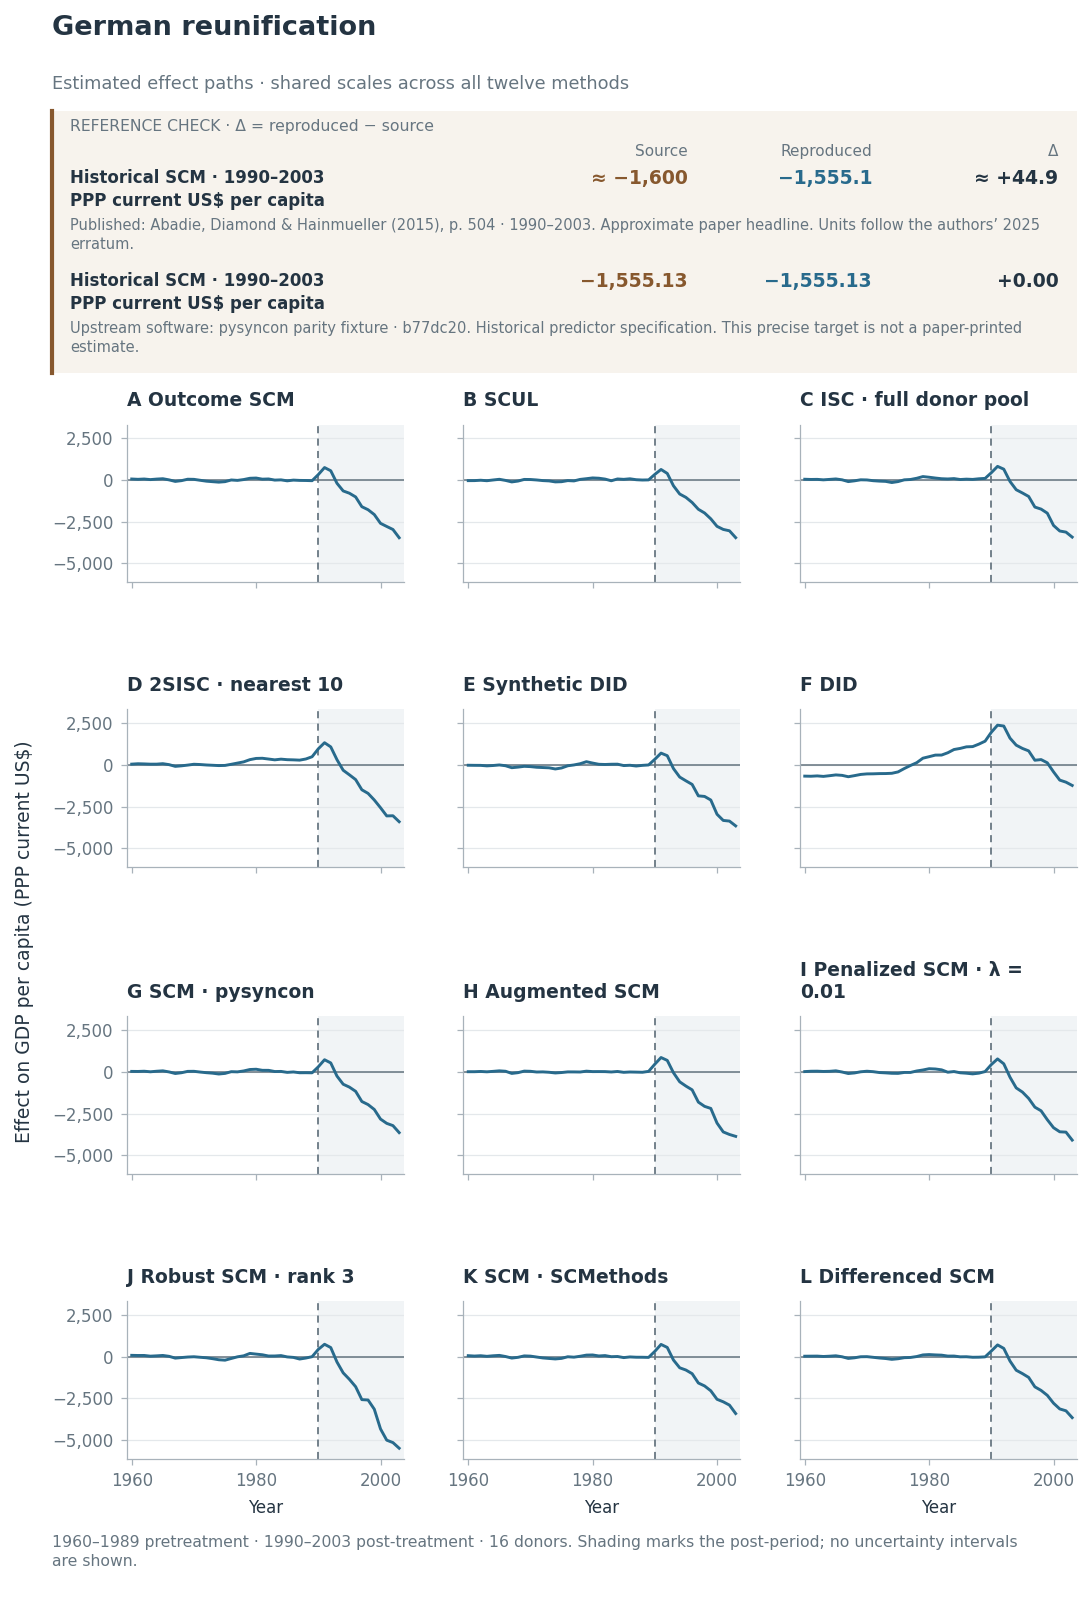

In [6]:
fig, axes = plot_effects(
    results, labels=display_labels,
    title=figure_details['case'],
    subtitle='Estimated effect paths · shared scales across all twelve methods',
    ylabel=figure_details['effect'], xlabel='Year',
    references=references,
    note=figure_details['periods'] + '. Shading marks the post-period; no uncertainty intervals are shown.',
)
effects_files = export_figure(fig, 'effects')
plt.show()

## Original SDID placebo inference

The original synthdid placebo variance estimator refits donor and time
weights in each of 200 resamples. The seed is fixed. These standard errors
apply to SDID alone; they are not intervals for the other methods.
The bootstrap and jackknife are undefined with only one treated unit.
California uses the authors' exact R sampling plan (seed 12345),
reproducing the paper's standard error 8.4 at its printed precision.
The other examples use NumPy seed 0 for reproducible new applications.

In [7]:
if paper_uncertainty is not None:
    np.testing.assert_allclose(results['Synthetic DID'].att, reference.att, atol=1e-12)
    uncertainty = paper_uncertainty
else:
    uncertainty = SyntheticDID().inference(
        panel, method='placebo', replications=200, random_state=0,
        estimate=results['Synthetic DID'],
    )
inference = pd.Series({
    'SDID ATT': results['Synthetic DID'].att,
    'Placebo standard error': uncertainty.standard_error,
    '95% normal interval': uncertainty.confidence_interval(),
    'Replications': 200,
}, name='SDID inference')
display(inference)
inference.to_csv(figure_dir / f'{name}-sdid-inference.csv')
np.savetxt(figure_dir / f'{name}-sdid-resamples.csv', uncertainty.resamples, delimiter=',', fmt='%d')
np.savetxt(figure_dir / f'{name}-sdid-draws.csv', uncertainty.draws, delimiter=',')

/tmp/ipykernel_84030/92762488.py:5: RuntimeWarning: SDID inference: 114 of 200 draws reached max_iter before the objective-decrease stopping rule; inspect solver_diagnostics
  uncertainty = SyntheticDID().inference(


SDID ATT                                             -1471.394896
Placebo standard error                                1488.216226
95% normal interval       (-4388.245099801436, 1445.455306826866)
Replications                                                  200
Name: SDID inference, dtype: object

## Inspect the donor coefficients

These are the fifteen donors with the largest absolute coefficient in
any method, not an exhaustive donor list. The coefficients are not
renormalized. SCUL and some augmented/robust estimates can have negative
weights or weight sums different from one. Intercepts and SDID time
weights are separate components; this table does not represent them.

In [8]:
weights = pd.concat({label: fit.weights for label, fit in results.items()}, axis=1)
weights.loc[weights.abs().max(axis=1).sort_values(ascending=False).index].head(15).round(4)

,Outcome SCM,SCUL,ISC (full donor pool),2SISC (nearest 10),Synthetic DID,DID,pysyncon SCM,Augmented SCM,Penalized SCM (0.01),"Robust SCM (rank 3, ridge 0.1)",SyntheticControlMethods SCM,Differenced SCM
Austria,0.3168,0.4609,0.1912,0.2034,0.1070,0.0625,0.2784,0.1563,0.4234,0.0651,0.3360,0.2641
USA,0.3421,0.3034,0.2197,0.2289,0.1645,0.0625,0.3213,0.2162,0.3069,0.0895,0.3416,0.3122
Denmark,0.0000,0.0000,0.0620,0.2083,0.0649,0.0625,0.0000,0.0294,0.1676,0.0832,0.0062,0.0909
Spain,0.0000,0.0000,0.0000,0.0000,0.0000,0.0625,0.0000,-0.1920,0.0000,0.0735,0.0000,0.0000
Italy,0.0537,0.1555,0.0907,0.0010,0.0725,0.0625,0.0829,0.1752,0.0000,0.0525,0.0805,0.0681
France,0.0590,0.0307,0.1085,0.1071,0.0767,0.0625,0.0653,0.1725,0.0000,0.0659,0.0000,0.0000
Switzerland,0.1053,0.0000,0.1256,0.0000,0.1536,0.0625,0.0930,0.0789,0.0000,0.0406,0.1103,0.0542
Norway,0.0274,0.0000,0.0661,0.0012,0.0958,0.0625,0.0356,0.0733,0.0000,0.1478,0.0246,0.0003
UK,0.0000,0.0000,0.0049,0.0000,0.0066,0.0625,0.0294,0.1384,0.0000,0.0889,0.0000,0.0000
Japan,0.0000,0.0000,0.0014,0.0044,0.0577,0.0625,0.0000,-0.1173,0.0000,0.0394,0.0000,0.0000


## Interpretation, exports and reproducibility

Negative effects mean the observed outcome is below its estimated
untreated path. These are point estimates under different restrictions,
tuning choices and identifying assumptions. They are not an uncertainty
distribution. The historical reference check is distinct from the new
comparison specifications and their stated tuning choices.

Each figure is exported at **7.2 inches wide** in three formats: PDF with
embedded fonts, SVG with editable text, and 300 dpi PNG. The local paths
are printed beside each embedded figure. Generated figures, CSV summaries,
and diagnostic files stay outside version control; rerunning the notebook
recreates them. Use vector formats for manuscripts and adjust figure size, labels
and captions through the plotting API before exporting to a journal's
requirements. Nothing depends on system fonts or an external TeX install.

`pysynth.placebo_test` provides in-space RMSPE-ratio diagnostics and a rank
p-value under exchangeability assumptions; it is not synthdid's placebo
variance estimator. The original SCUL scanner-data and ISC/costofcare
survey studies are not reproduced here. Re-run from a fresh kernel to
reproduce the source checks, estimates and figures together.